# Система прогнозирования продаж для «Прилавка»

## Описание задачи

Ваш клиент — компания «Прилавок», новая сеть дарксторов в России, специализирующаяся на быстрой доставке продуктов и товаров повседневного спроса. Компания работает с 2023 года и управляет более чем 45 дарксторами.

**Бизнес-проблема**

Эффективность дарксторов критически зависит от точности управления запасами. Текущая система планирования закупок работает на субъективных оценках аналитиков, что приводит к разным проблемам:
- К дефициту товаров в пиковые периоды (недополучение 3–5% выручки).
- К избыточным запасам и списаниям продуктов с коротким сроком годности (2–3% от выручки).
- К неэффективному использованию времени аналитиков (15–20 часов в неделю на ручное планирование).

**Цель проекта**

Разработать автоматизированную систему прогнозирования недельных продаж для каждого отдела во всех дарксторах с использованием машинного обучения (модель CatBoost). Система будет работать в режиме пакетного внедрения с недельным циклом: модель будет переобучаться каждое воскресенье вечером, а к понедельнику утром прогнозы будут готовы для передачи в систему планирования закупок.

## Описание данных

Для работы доступны исторические данные о продажах за февраль 2023 — октябрь 2025, организованные в виде нескольких таблиц в PostgreSQL:

1. Таблица `sales` — исторические данные о продажах:
   - `Store` — номер даркстора (1–45).
   - `Dept` — номер отдела внутри даркстора (1–99).
   - `Date` — неделя (дата начала недели).
   - `Weekly_Sales` — недельные продажи (руб., целевая переменная).
   - `IsHoliday` — признак праздничной недели.

2. Таблица `stores` — информация о дарксторах:
   - `Store` — номер даркстора.
   - `Type` — тип даркстора (A, B, C).
   - `Size` — размер даркстора в условных единицах.

3. Таблица `features` — внешние факторы:
   - `Store`, `Date` — идентификаторы.
   - `Temperature` — средняя температура за неделю.
   - `Fuel_Price` — средняя цена бензина.
   - `MarkDown1-5` — факторы рекламных акций и скидок.
   - `CPI` — индекс потребительских цен.
   - `Unemployment` — уровень безработицы.

4. Таблица `plan` — данные для инференса (ноябрь 2025 — июль 2026), содержит те же столбцы, что и `sales`, кроме `Weekly_Sales`.

## План работы

Проект состоит из двух частей. В этом ноутбуке вы выполните первую:

1. Первичный анализ и очистка данных.
2. Предобработка и создание признаков.
3. Мониторинг стабильности признаков (PSI).
4. Обучение модели CatBoost и оценка качества.



In [1]:
!pip install catboost

In [2]:
# Здесь все необходимые импорты

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import psycopg2

import warnings
warnings.filterwarnings("ignore")

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Фиксируем `random_state` для воспроизводимости результатов.

In [3]:
RANDOM_STATE = 42

### Шаг 1. Первичный анализ данных

**Задача:** подключитесь к базе данных PostgreSQL и загрузите данные для анализа.

**Важно:** не храните креды в коде! Используйте переменные окружения или Airflow Variables и Connections.

In [ ]:
import os
from dotenv import load_dotenv

# Параметры подключения читаются из файла .env (шаблон: .env.example), в код они не записываются
load_dotenv()

DB_USER = os.getenv("DB_USER")
DB_PASS = os.getenv("DB_PASS")
DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT", "6432")
DB_NAME = os.getenv("DB_NAME")

# Прямое подключение через psycopg2
conn = psycopg2.connect(
    dbname=DB_NAME,
    user=DB_USER,
    password=DB_PASS,
    host=DB_HOST,
    port=DB_PORT
)

**Задача:** загрузите три таблицы из PostgreSQL: `sales`, `stores`, `features`.

Используйте SQL-запросы для загрузки данных через функцию `pd.read_sql_query()`.

In [5]:
try:
    # Читаем таблицы напрямую из базы в Pandas DataFrame
    query = "SELECT * FROM public.sales;"
    df_sales = pd.read_sql(query, con=conn)

    query = "SELECT * FROM public.stores;"
    df_stores = pd.read_sql(query, con=conn)

    query = "SELECT * FROM public.features;"
    df_features = pd.read_sql(query, con=conn)

    print(f"Размерность полученных DataFrame:, df_sales - {df_sales.shape}, df_stores - {df_stores.shape}, df_features - {df_features.shape}")

finally:
    # закрываем соединение после чтения данных
    conn.close()

Размерность полученных DataFrame:, df_sales - (421570, 5), df_stores - (45, 3), df_features - (421570, 12)


**Задача:** обработайте пропуски и дубликаты в каждой таблице.

Рекомендации по обработке пропусков:
- Для непрерывных переменных — заполнить средним значением.
- Для категориальных переменных — заполнить модой.
- Полные дубликаты строк — удалить.

Перед обработкой изучите структуру пропусков и их причины.

Проверка пропусков и дубликатов

In [6]:
def explore_data(df, name):
    """
    Функция для первичного анализа датафрейма.
    Выводит размерность, первые строки, информацию о типах данных,
    количество пропусков и дубликатов.
    """

    print(f"Размерность (строки, столбцы): {df.shape}")

    # Первые 5 строк
    display(df.head())

    # Информация о типах данных
    df.info()

    # Анализ пропусков
    missing = df.isna().sum()
    if missing.sum() > 0:
        print(f"\n Найдены пропуски! Количество по столбцам:\n{missing[missing > 0]}")
    else:
        print("\n Пропусков в данных не обнаружено.")

    # Анализ дубликатов
    dups = df.duplicated().sum()
    if dups > 0:
        print(f"\n Найдены полные дубликаты строк: {dups}")
    else:
        print("\n Полных дубликатов строк не обнаружено.")

In [7]:
# Применяем функцию
explore_data(df_sales, 'df_sales')

Размерность (строки, столбцы): (421570, 5)


,store,dept,date,weekly_sales,is_holiday
0,1,1,2023-02-05,24924.50,False
1,29,5,2023-02-05,15552.08,False
2,29,6,2023-02-05,3200.22,False
3,29,7,2023-02-05,10820.05,False
4,29,8,2023-02-05,20055.64,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store         421570 non-null  int64  
 1   dept          421570 non-null  int64  
 2   date          421570 non-null  object 
 3   weekly_sales  421570 non-null  float64
 4   is_holiday    421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB

 Пропусков в данных не обнаружено.

 Полных дубликатов строк не обнаружено.


In [8]:
# Приведем признак date к формату datetime
df_sales['date'] = pd.to_datetime(df_sales['date'])

In [9]:
explore_data(df_stores, 'df_stores')

Размерность (строки, столбцы): (45, 3)


,store,type,size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45 entries, 0 to 44
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   store   45 non-null     int64 
 1   type    45 non-null     object
 2   size    45 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 1.2+ KB

 Пропусков в данных не обнаружено.

 Полных дубликатов строк не обнаружено.


In [10]:
explore_data(df_features, 'df_features')

Размерность (строки, столбцы): (421570, 12)


,store,dept,date,temperature,fuel_price,factor1,factor2,factor3,factor4,factor5,cpi,unemployment
0,1,1,2023-02-05,42.31,2.572,7028.8,NaN,NaN,NaN,NaN,211.096358,8.106
1,29,5,2023-02-05,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064
2,29,6,2023-02-05,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064
3,29,7,2023-02-05,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064
4,29,8,2023-02-05,24.36,2.788,7028.8,NaN,NaN,NaN,NaN,131.527903,10.064


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 12 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   store         421570 non-null  int64  
 1   dept          421570 non-null  int64  
 2   date          421570 non-null  object 
 3   temperature   421570 non-null  float64
 4   fuel_price    421570 non-null  float64
 5   factor1       421570 non-null  float64
 6   factor2       111248 non-null  float64
 7   factor3       137091 non-null  float64
 8   factor4       134967 non-null  float64
 9   factor5       151432 non-null  float64
 10  cpi           421570 non-null  float64
 11  unemployment  421570 non-null  float64
dtypes: float64(9), int64(2), object(1)
memory usage: 38.6+ MB

 Найдены пропуски! Количество по столбцам:
factor2    310322
factor3    284479
factor4    286603
factor5    270138
dtype: int64

 Полных дубликатов строк не обнаружено.


In [11]:
# Приведем признак date к формату datetime
df_features['date'] = pd.to_datetime(df_features['date'])

Заполняем пропуски в factor значением 0, чт значит, что акции не было
* factor2    
* factor3    
* factor4    
* factor5


In [12]:
# Выбираем нужные столбцы и считаем по ним среднее
nan_cols = ['factor2', 'factor3', 'factor4', 'factor5']

# Заполняем пропуски значением 0 каждого соответствующего столбца
df_features[nan_cols] = df_features[nan_cols].fillna(0)

**Задача:** визуализируйте распределение продаж по времени (по месяцам и неделям).

Цель: выявить визуально наличие сезонности в данных. Обратите внимание:
- На периодические всплески (праздники, выходные).
- На общий тренд (рост и спад продаж).
- На аномальные периоды.

Графический анализ количественных и категориальных данных

In [13]:
# Настройки для графиков
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

def plot_continuous_feature_distribution(df, column, title=None):
    """Функция для построения гистограммы и boxplot непрерывного числового признака"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Гистограмма
    sns.histplot(df[column].dropna(), bins=50, kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Распределение: {column}' if title is None else title)
    axes[0].set_xlabel(column)
    axes[0].set_ylabel('Количество')

    # Boxplot
    sns.boxplot(y=df[column].dropna(), ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Boxplot: {column}')
    axes[1].set_ylabel(column)

    plt.tight_layout()
    plt.show()

    # Вывод статистик
    print(f"\n Статистики для '{column}':")
    print(f"  Среднее: {df[column].mean():.2f}")
    print(f"  Медиана: {df[column].median():.2f}")
    print(f"  Мин: {df[column].min():.2f}")
    print(f"  Макс: {df[column].max():.2f}")
    print(f"  Стандартное отклонение: {df[column].std():.2f}")

In [14]:
numerical_features = df_sales.select_dtypes(include=['int64', 'float64']).columns

numerical_features

Index(['store', 'dept', 'weekly_sales'], dtype='object')

In [15]:
# Анализ непрерывных и дискретных признаков
analysis_df = pd.DataFrame({
    'Тип данных (Dtype)': df_sales[numerical_features].dtypes,
    'Кол-во уникальных значений (nunique)': df_sales[numerical_features].nunique(),
    'Пример значений': [df_sales[col].unique()[:5] for col in numerical_features] # первые 5 уникальных значений
})

display(analysis_df)

,Тип данных (Dtype),Кол-во уникальных значений (nunique),Пример значений
store,int64,45,"[1, 29, 2, 28, 27]"
dept,int64,81,"[1, 5, 6, 7, 8]"
weekly_sales,float64,359464,"[24924.5, 15552.08, 3200.22, 10820.05, 20055.64]"


store, dept - дискретные признаки

weekly_sales	- непрерывный признак

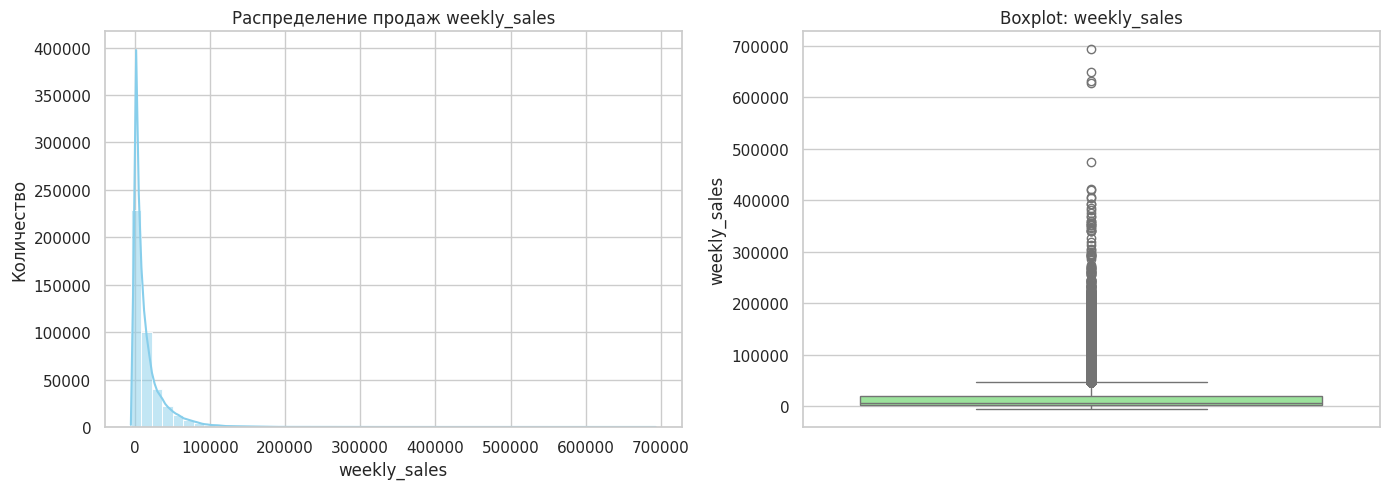


 Статистики для 'weekly_sales':
  Среднее: 15981.26
  Медиана: 7612.03
  Мин: -4988.94
  Макс: 693099.36
  Стандартное отклонение: 22711.18


In [16]:
plot_continuous_feature_distribution(df_sales, 'weekly_sales', title= 'Распределение продаж weekly_sales')

Динамика суммарных продаж сети по неделям

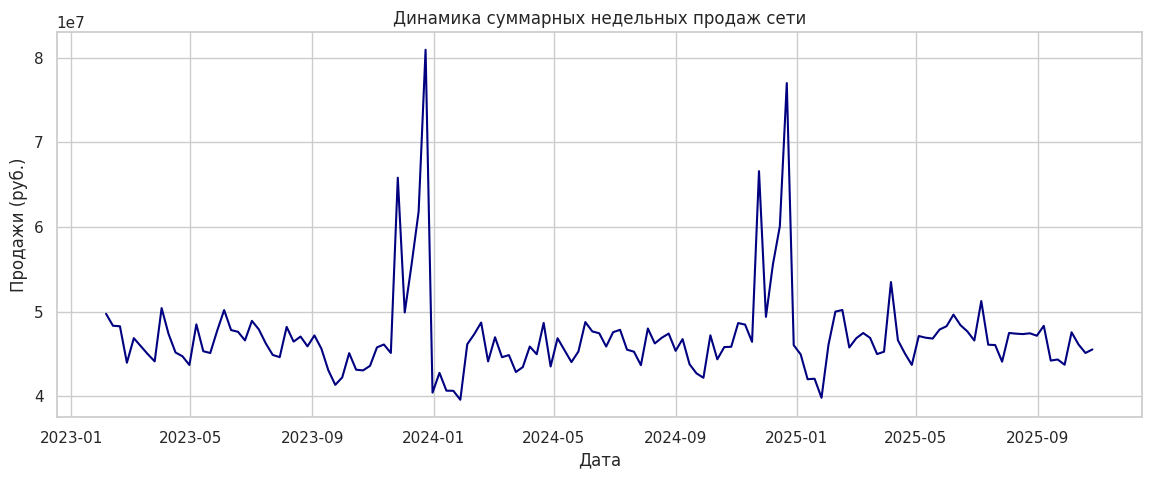

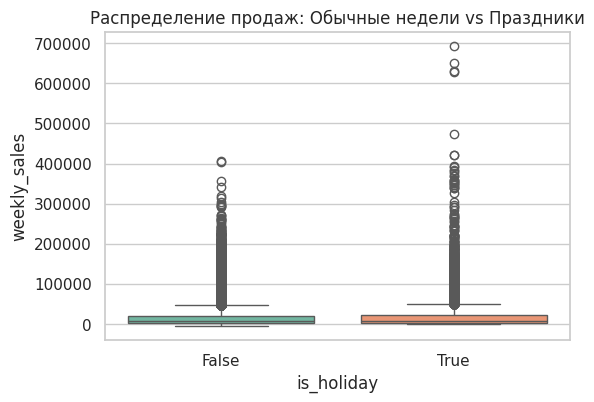

In [17]:
# Общий тренд продаж сети по времени
plt.figure(figsize=(14, 5))
df_total_sales = df_sales.groupby('date')['weekly_sales'].sum().reset_index()
sns.lineplot(data=df_total_sales, x='date', y='weekly_sales', color='navy')
plt.title('Динамика суммарных недельных продаж сети')
plt.xlabel('Дата')
plt.ylabel('Продажи (руб.)')
plt.grid(True)
plt.show()

# Влияние праздников на продажи (Boxplot)
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_sales, x='is_holiday', y='weekly_sales', palette='Set2')
plt.title('Распределение продаж: Обычные недели vs Праздники')
plt.show()

Агрегированные продажи по месяцам года

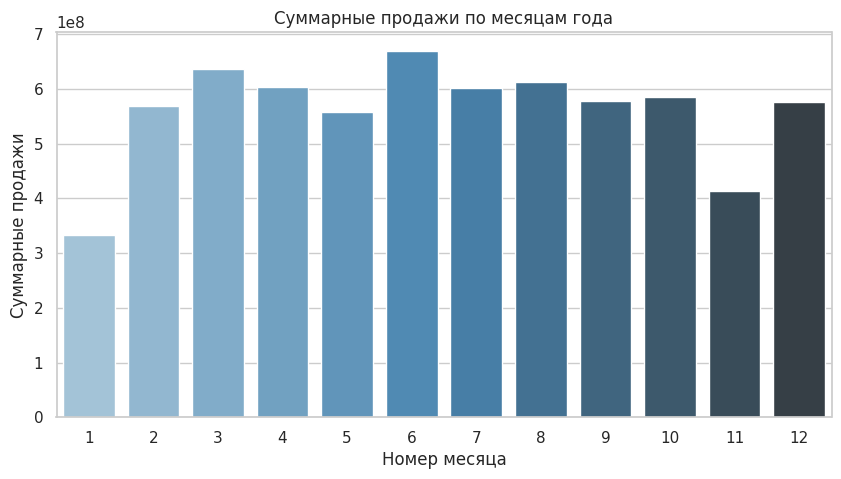

In [18]:
df_sales['month'] = pd.to_datetime(df_sales['date']).dt.month

plt.figure(figsize=(10, 5))
sns.barplot(data=df_sales, x='month', y='weekly_sales', estimator=sum, ci=None, palette='Blues_d')
plt.title('Суммарные продажи по месяцам года')
plt.xlabel('Номер месяца')
plt.ylabel('Суммарные продажи')
plt.show()

По визуализации можно сделать вывод, что в праздники сумма продаж возрастала

Наблюдаются рост продаж в предновогодние праздники (в декабре) и в июне

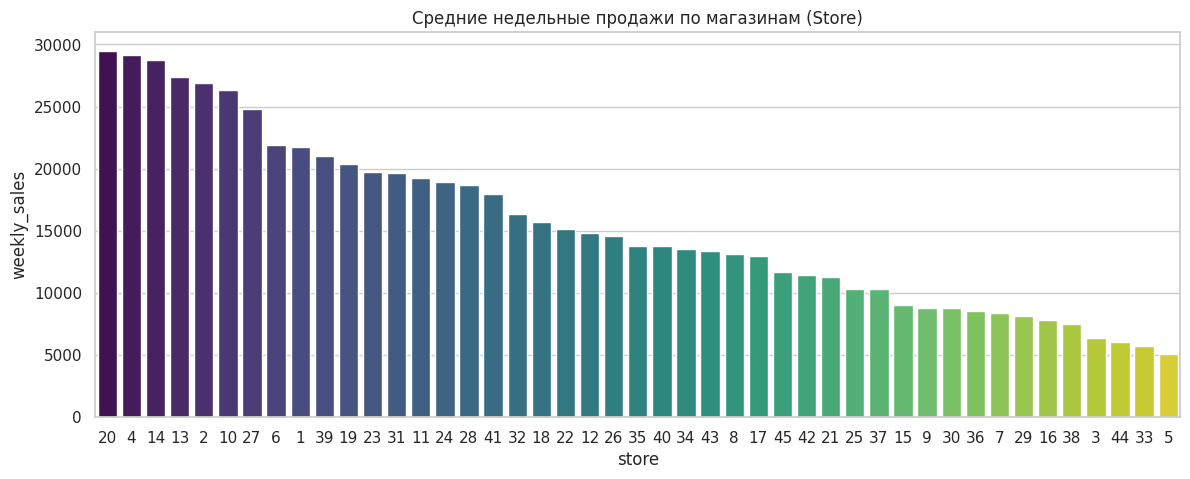

In [19]:
# Средние продажи по магазинам (сортировка по убыванию)
plt.figure(figsize=(14, 5))
store_order = df_sales.groupby('store')['weekly_sales'].mean().sort_values(ascending=False).index

sns.barplot(data=df_sales, x='store', y='weekly_sales', order=store_order, ci=None, palette='viridis')
plt.title('Средние недельные продажи по магазинам (Store)')
plt.show()

Анализ распределения по Дарксторам (Store) и Отделам (Dept)

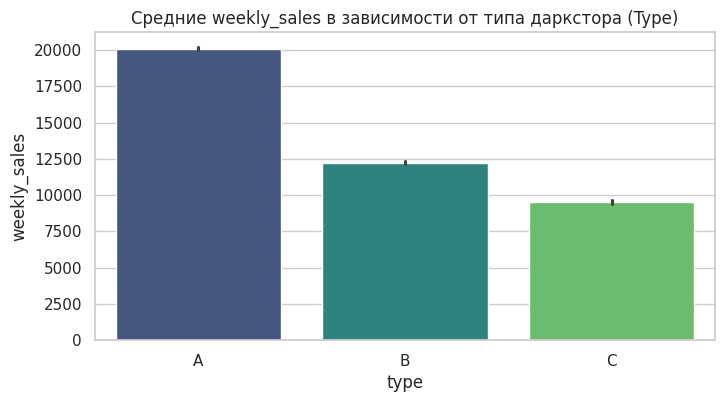

In [20]:
# Средние продажи по типам дарксторов (A, B, C)
df_merged = df_sales.merge(df_stores, on='store')

plt.figure(figsize=(8, 4))
sns.barplot(data=df_merged, x='type', y='weekly_sales', palette='viridis')
plt.title('Средние weekly_sales в зависимости от типа даркстора (Type)')
plt.show()

Больше всего продаж в крупных A дарксторах, меньще всего в C мелких

**Задача:** объедините три таблицы в одну для дальнейшего анализа.

Используйте операции `merge()` для соединения таблиц по общим ключам.

In [21]:
# Оптимизируем типы данных для экономии памяти - из-за ошибок использования ОЗУ
for df in [df_sales, df_features, df_stores]:
    for col in df.select_dtypes(include=['int64', 'float64']).columns:
        df[col] = pd.to_numeric(df[col], downcast='unsigned' if 'int' in str(df[col].dtype) else 'float')

Т.к. в описании таблиц сказано:
- df_sales['date'] - Неделя, точнее — **дата начала недели**, формат YYYY-MM-DD
- df_features['date'] - Неделя, точнее — **дата окончания недели**


In [22]:
df_sales['date'].min()

Timestamp('2023-02-05 00:00:00')

In [23]:
df_features['date'].min()

Timestamp('2023-02-05 00:00:00')

In [24]:
# Сдвигаем дату в df_features к дате начала недели (если разница 6 дней)
# Проверь разницу на первых строках: df_sales['date'].min() и df_features['date'].min()
# Если дата окончания в features ровно на 6 дней позже даты начала в sales:
df_features['date_start'] = df_features['date'] - pd.Timedelta(days=6) # или 7, в зависимости от разницы

In [25]:
# Выравниваем даты в df_features (сдвигаем к дате начала недели, как в df_sales)
date_offset = (df_features['date'].min() - df_sales['date'].min()).days
print(f"Сдвиг дат между features и sales составляет {date_offset} дней")

Сдвиг дат между features и sales составляет 0 дней


In [26]:
df_features['date_aligned'] = df_features['date'] - pd.Timedelta(days=date_offset)

In [27]:
# Объединяем таблицы по ключам
# Присоединяем информацию о магазинах по ключу 'store'
df_full = df_sales.merge(df_stores, on='store', how='left')

In [28]:
# Присоединяем features по 3 ключам: 'store', 'dept' и выровненной дате 'date_aligned'
df_full = df_full.merge(
    df_features.drop(columns=['date']),
    left_on=['store', 'dept', 'date'],
    right_on=['store', 'dept', 'date_aligned'],
    how='left'
).drop(columns=['date_aligned'])

In [29]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   store         421570 non-null  uint8         
 1   dept          421570 non-null  uint8         
 2   date          421570 non-null  datetime64[ns]
 3   weekly_sales  421570 non-null  float64       
 4   is_holiday    421570 non-null  bool          
 5   month         421570 non-null  int32         
 6   type          421570 non-null  object        
 7   size          421570 non-null  uint32        
 8   temperature   421570 non-null  float32       
 9   fuel_price    421570 non-null  float32       
 10  factor1       421570 non-null  float64       
 11  factor2       421570 non-null  float64       
 12  factor3       421570 non-null  float64       
 13  factor4       421570 non-null  float64       
 14  factor5       421570 non-null  float64       
 15  cpi           421

In [30]:
# Удаляем технический столбец date_start
df_full = df_full.drop(columns=['date_start'])

In [31]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 17 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   store         421570 non-null  uint8         
 1   dept          421570 non-null  uint8         
 2   date          421570 non-null  datetime64[ns]
 3   weekly_sales  421570 non-null  float64       
 4   is_holiday    421570 non-null  bool          
 5   month         421570 non-null  int32         
 6   type          421570 non-null  object        
 7   size          421570 non-null  uint32        
 8   temperature   421570 non-null  float32       
 9   fuel_price    421570 non-null  float32       
 10  factor1       421570 non-null  float64       
 11  factor2       421570 non-null  float64       
 12  factor3       421570 non-null  float64       
 13  factor4       421570 non-null  float64       
 14  factor5       421570 non-null  float64       
 15  cpi           421

**Задача:** оцените корреляцию целевой переменной `Weekly_Sales` с другими признаками.

Используйте метод `.corr()` для расчёта корреляционной матрицы. Ответьте на вопросы:
- Какие признаки сильнее всего коррелируют с продажами?
- Есть ли сильно коррелирующие между собой признаки (мультиколлинеарность)?

Тепловая карта факторов внешней среды (features)

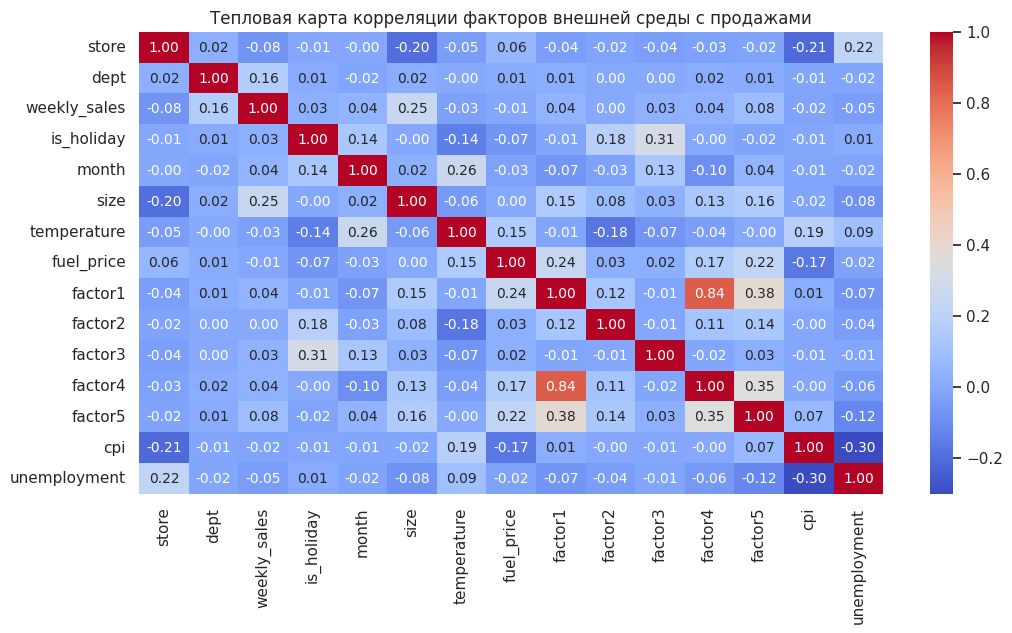

In [32]:
# Создаем отдельный сэмпл только для корреляции
df_sample = df_full.sample(n=5000, random_state=RANDOM_STATE)

sns.heatmap(df_sample.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Тепловая карта корреляции факторов внешней среды с продажами')
plt.show()

Не наблюдается сильной корреляции между целевой переменной weekly_sales И другими признаками

Наблюдается корреляция между признаками:

* factor1 - factor4  = 0.84


Вывод: можно не передать для обучения модели factor 1

**Задача:** обработайте аномалии в продажах.

Подсказка: могут ли продажи быть отрицательными? Решите, как с ними поступить.

Обоснуйте свой выбор.

Визуализация для анализа аномалий и выбросов (Отрицательные продажи)

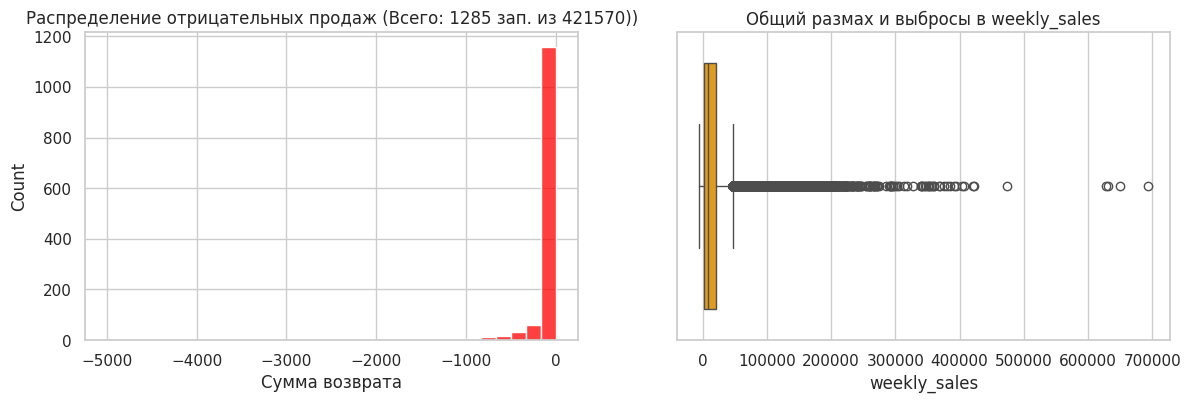

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 1. Распределение отрицательных продаж (возвратов)
neg_sales = df_full[df_full['weekly_sales'] < 0]['weekly_sales']
sns.histplot(neg_sales, ax=axes[0], color='red', bins=30)
axes[0].set_title(f'Распределение отрицательных продаж (Всего: {len(neg_sales)} зап. из {len(df_full)}))')
axes[0].set_xlabel('Сумма возврата')

# 2. Общее распределение продаж с выбросами
sns.boxplot(x=df_full['weekly_sales'], ax=axes[1], color='orange')
axes[1].set_title('Общий размах и выбросы в weekly_sales')
plt.show()

- weekly_sale содержит отрицательные выбросы - 1285 записей, что составляет 0.3%

In [34]:
df_full = df_full.drop(df_full[df_full['weekly_sales'] < 0].index)
len(df_full)

420285

**Задача:** исследуйте аномально высокие продажи.

Найдите записи с очень высокими продажами (например, топ 0.01% или выше 99.99% квантиля). Попробуйте найти закономерности:
- В какое время года они происходят?
- Связаны ли они с праздниками?
- Какие типы дарксторов и отделы демонстрируют пиковые продажи?

In [35]:
# 99.99 квантиль
quantile_99 = df_full['weekly_sales'].quantile(0.999)

df_over_99q = df_full[df_full['weekly_sales'] > quantile_99].copy()

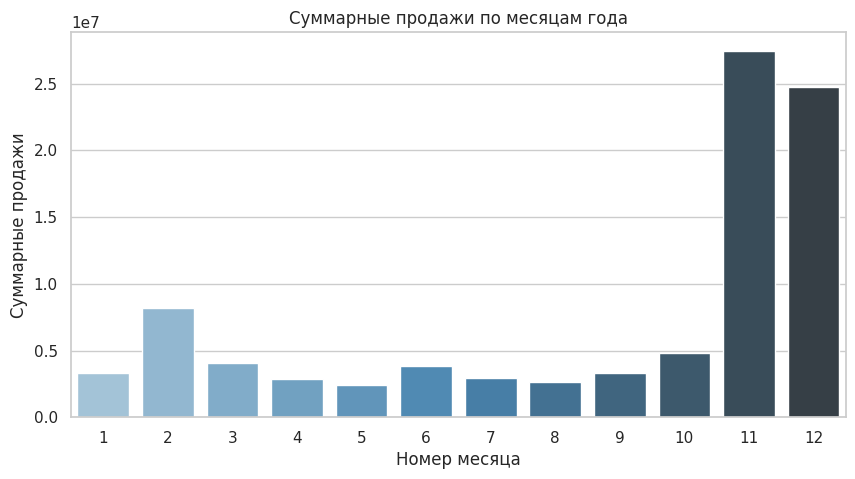

In [36]:
# Связь с месецами года
df_over_99q['month'] = pd.to_datetime(df_over_99q['date']).dt.month

plt.figure(figsize=(10, 5))
sns.barplot(data=df_over_99q, x='month', y='weekly_sales', estimator=sum, ci=None, palette='Blues_d')
plt.title('Суммарные продажи по месяцам года')
plt.xlabel('Номер месяца')
plt.ylabel('Суммарные продажи')
plt.show()

- Пик продаж приходится на ноябрь и декабрь

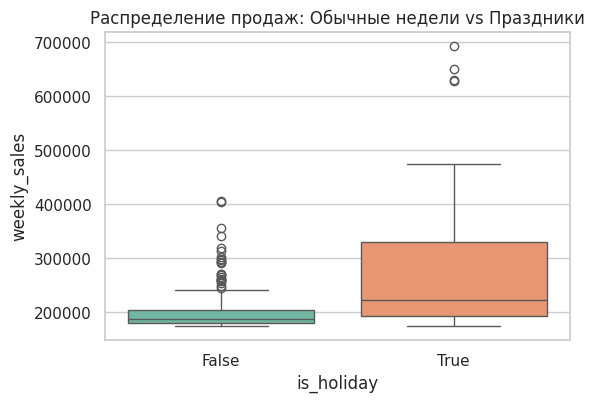

In [37]:
# Визуализируем связь с праздниками is_holiday
plt.figure(figsize=(6, 4))
sns.boxplot(data=df_over_99q, x='is_holiday', y='weekly_sales', palette='Set2')
plt.title('Распределение продаж: Обычные недели vs Праздники')
plt.show()

- В праздничные дни очень высокие продажи

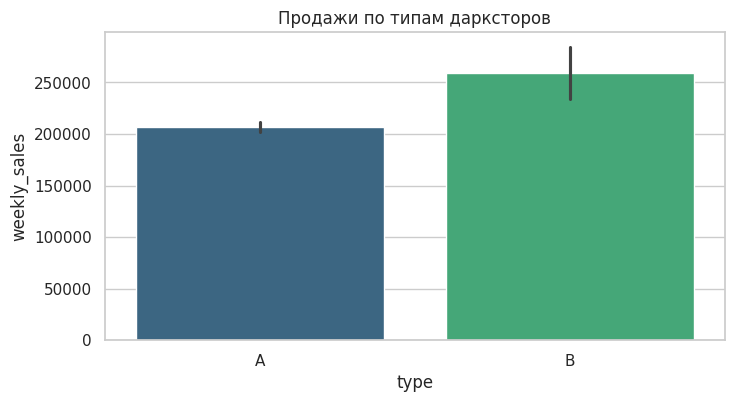

In [38]:
# Визуализируем распределение по типам дарксторов (A,B,C)
plt.figure(figsize=(8,4))
sns.barplot(df_over_99q,x='type',y='weekly_sales',palette='viridis')
plt.title('Продажи по типам дарксторов')
plt.show()

- Очень высокие продажи присутствуют только в 2 типах дарксторов: в Крупных А и Средник В дарксторах

- Больше всего очень высоких продаж в средних дарксторах B

In [39]:
# Взаимосвязь с отделами
df_over_99q['dept'].value_counts()

,count
dept,
92,240
72,104
7,45
95,23
5,9


### Шаг 2. Предобработка признаков и feature engineering

**Задача:** реализуйте функцию `create_temporal_features` для извлечения временных признаков из столбца `Date`.

Извлеките из даты:
- Месяц (`month`).
- Квартал (`quarter`).
- Год (`year`).

Эти признаки помогут модели уловить сезонные паттерны.

In [40]:
def create_temporal_features(df) -> pd.DataFrame:
    df['date'] = pd.to_datetime(df['date'])
    df['month'] = df['date'].dt.month
    df['quarter'] = df['date'].dt.quarter
    df['year'] = df['date'].dt.year
    return df

df_full = create_temporal_features(df_full)

In [41]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
Index: 420285 entries, 0 to 421569
Data columns (total 19 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   store         420285 non-null  uint8         
 1   dept          420285 non-null  uint8         
 2   date          420285 non-null  datetime64[ns]
 3   weekly_sales  420285 non-null  float64       
 4   is_holiday    420285 non-null  bool          
 5   month         420285 non-null  int32         
 6   type          420285 non-null  object        
 7   size          420285 non-null  uint32        
 8   temperature   420285 non-null  float32       
 9   fuel_price    420285 non-null  float32       
 10  factor1       420285 non-null  float64       
 11  factor2       420285 non-null  float64       
 12  factor3       420285 non-null  float64       
 13  factor4       420285 non-null  float64       
 14  factor5       420285 non-null  float64       
 15  cpi           420285 n

In [42]:
assert 'month' in df_full.columns, 'Месяц не создан!'
assert 'quarter' in df_full.columns, 'Квартал не создан!'
assert 'year' in df_full.columns, 'Год не создан!'

**Задача:** cоздайте агрегированные признаки в функции `create_avg_sales_feature` — средние продажи по комбинации «даркстор и отдел».

**Важно: Избегайте утечки данных!**

При создании агрегатов для каждой строки используйте только данные **до** этой даты:
- Для даты 2025-09-08 считайте среднее по данным с начала до 2025-09-07 включительно.
- Для даты 2025-09-15 считайте среднее по данным с начала до 2025-09-14 включительно.

Это критически важно, чтобы модель не использовала информацию из будущего!

In [43]:
def create_avg_sales_feature(df):
    # Создаем копию
    df = df.copy()

    # Сортируем по времени
    df = df.sort_values(by=['store', 'dept', 'date']).reset_index(drop=True)

    # Считаем накопительное среднее со сдвигом строго внутри каждой группы store + dept
    # .transform() гарантирует, что порядок и размерность строк сохранятся
    df['avg_sales_before'] = (
        df.groupby(['store', 'dept'])['weekly_sales']
        .transform(lambda x: x.expanding().mean().shift(1))
    )

    return df

# Применяем функцию
df_full = create_avg_sales_feature(df_full)

In [44]:
assert 'avg_sales_before' in df_full.columns, 'Признак средних продаж не создан!'

**Задача:** создайте лаговые признаки в функции `create_lag_features` — продажи 1, 2 и 4 недели назад.

Лаговые признаки позволяют модели учитывать историю продаж:
- `sales_1week_ago` — продажи неделю назад.
- `sales_2week_ago` — продажи 2 недели назад.
- `sales_4week_ago` — продажи 4 недели назад.

Это одни из самых важных признаков для прогнозирования временных рядов!

In [45]:
def create_lag_features(df):
    #raise NotImplementedError('Функция create_lag_features не реализована!')
    # Делаем копию, чтобы не изменять исходный df напрямую
    df_temp = df.copy()

    # Сортируем по магазину, отделу и дате
    df_temp = df_temp.sort_values(by=['store', 'dept', 'date']).reset_index(drop=True)

    # Создаем лаговые признаки с помощью transform и shift
    # lambda x: x.shift(N) сдвигает историю продаж внутри каждой группы (store + dept)
    df_temp['sales_1week_ago'] = df_temp.groupby(['store', 'dept'])['weekly_sales'].transform(lambda x: x.shift(1))
    df_temp['sales_2week_ago'] = df_temp.groupby(['store', 'dept'])['weekly_sales'].transform(lambda x: x.shift(2))
    df_temp['sales_4week_ago'] = df_temp.groupby(['store', 'dept'])['weekly_sales'].transform(lambda x: x.shift(4))

    return df_temp

# Применяем функцию
df_full = create_lag_features(df_full)

In [46]:
assert 'sales_1week_ago' in df_full.columns, 'Признак sales_1week_ago не создан!'
assert 'sales_2week_ago' in df_full.columns, 'Признак sales_2week_ago не создан!'
assert 'sales_4week_ago' in df_full.columns, 'Признак sales_4week_ago не создан!'

**Задача:** cоздайте признаки скользящего среднего продаж за последние 2 и 4 недели в функции `create_rolling_features`.

Скользящее среднее сглаживает колебания и показывает общий тренд:
- `mean_sales_2week` — среднее продаж за последние 2 недели.
- `mean_sales_4week` — среднее продаж за последние 4 недели.

Эти признаки помогают уловить краткосрочные и среднесрочные тренды.

In [47]:
def create_rolling_features(df):
    #raise NotImplementedError('Функция create_rolling_features не реализована!')
    df_temp = df.copy()
    df_temp = df_temp.sort_values(by=['store','dept','date']).reset_index(drop=True)
    df_temp['mean_sales_2week'] = df_temp.groupby(['store', 'dept'])['weekly_sales'].transform(lambda x: x.rolling(window=2).mean().shift(1))
    df_temp['mean_sales_4week'] = df_temp.groupby(['store', 'dept'])['weekly_sales'].transform(lambda x: x.rolling(window=4).mean().shift(1))
    return df_temp

df_full = create_rolling_features(df_full)

In [48]:
assert 'mean_sales_2week' in df_full.columns, 'Признак mean_sales_2week не создан!'
assert 'mean_sales_4week' in df_full.columns, 'Признак mean_sales_4week не создан!'

**Задача:** удалите строки с пропусками.

После создания лаговых и агрегированных признаков неизбежно появятся пропуски (особенно для первых недель, где нет истории). Удалите такие строки с помощью `dropna()`.

In [49]:
df_full = df_full.dropna()
df_full.isna().sum()

,0
store,0
dept,0
date,0
weekly_sales,0
is_holiday,0
month,0
type,0
size,0
temperature,0
fuel_price,0


### Шаг 3. Мониторинг стабильности признаков

**Задача:** разделите данные на обучающую и валидационную выборки **по времени**.

Разделение:
- **Обучение**: февраль 2023 — август 2025.
- **Валидация**: сентябрь 2025 — октябрь 2025.

Такое разделение имитирует реальное применение модели: обучаем на прошлых данных, проверяем на будущих.

In [50]:
cutoff_date = '2025-09-01'  # месяц разделения сентябрь
train_data = df_full[df_full['date'] < cutoff_date]
val_data = df_full[df_full['date'] >= cutoff_date]

print(f"Обучение: {train_data['date'].min().strftime('%Y-%m-%d')} — {train_data['date'].max().strftime('%Y-%m-%d')} | Строк: {len(train_data)}")
print(f"Валидация: {val_data['date'].min().strftime('%Y-%m-%d')} — {val_data['date'].max().strftime('%Y-%m-%d')} | Строк: {len(val_data)}")

Обучение: 2023-03-05 — 2025-08-31 | Строк: 383541
Валидация: 2025-09-07 — 2025-10-26 | Строк: 23647


**Задача:** рассчитайте PSI для всех признаков.

PSI измеряет стабильность распределения признака между обучающей и валидационной выборками:
- **PSI < 0.1** — признак стабилен, можно использовать.
- **0.1 ≤ PSI < 0.2** — умеренный дрейф, требуется внимание.
- **PSI ≥ 0.2** — значительный дрейф, признак нестабилен.

In [51]:
# Функция для расчета PSI
def calculate_psi(expected, actual, buckets=10, epsilon=1e-10):

    # Если данные пустые после удаления NaN, возвращаем NaN
    if len(expected) == 0 or len(actual) == 0:
        return np.nan

    # Находим границы бинов по совместному диапазону значений
    min_val = min(expected.min(), actual.min())
    max_val = max(expected.max(), actual.max())

    # Если все значения одинаковы (нет разброса), PSI равен 0
    if min_val == max_val:
        return 0.0

    breaks = np.linspace(min_val, max_val, buckets + 1)

    # Рассчитываем доли элементов в каждом бине
    expected_counts, _ = np.histogram(expected, bins=breaks)
    actual_counts, _ = np.histogram(actual, bins=breaks)

    expected_pct = expected_counts / len(expected)
    actual_pct = actual_counts / len(actual)

    # Избавляемся от нулевых долей с помощью epsilon, чтобы не получить log(0) или деление на 0
    expected_pct = np.where(expected_pct == 0, epsilon, expected_pct)
    actual_pct = np.where(actual_pct == 0, epsilon, actual_pct)

    # Считаем PSI (векторизованная формула)
    psi_value = np.sum((actual_pct - expected_pct) * np.log(actual_pct / expected_pct))

    return psi_value

In [52]:
# Расчет PSI
# Выбираем только числовые столбцы (исключаем float/int текстовые идентификаторы, даты и целевую переменную)
numeric_cols = train_data.select_dtypes(include=['number']).columns

psi_results = {}

bad_psi = []
for col in numeric_cols:
    # Пропускаем целевую переменную, идентификаторы дарксторов и отделов
    if col in ['weekly_sales', 'store', 'dept']:
        continue

    psi_val = calculate_psi(train_data[col], val_data[col])
    psi_results[col] = psi_val

    # Форматированный вывод с интерпретацией
    if psi_val < 0.1:
        status = "✅ Стабилен"
    elif psi_val < 0.2:
        status = "⚠️ Умеренный дрейф"
    else:
        status = "🚨 Сильный дрейф!"
        bad_psi.append(col)

    print(f"PSI для {col:15s}: {psi_val:.4f}  | {status}")

PSI для month          : 19.6586  | 🚨 Сильный дрейф!
PSI для size           : 0.0001  | ✅ Стабилен
PSI для temperature    : 3.1204  | 🚨 Сильный дрейф!
PSI для fuel_price     : 11.7986  | 🚨 Сильный дрейф!
PSI для factor1        : 0.3317  | 🚨 Сильный дрейф!
PSI для factor2        : 0.4499  | 🚨 Сильный дрейф!
PSI для factor3        : 0.1182  | ⚠️ Умеренный дрейф
PSI для factor4        : 0.2783  | 🚨 Сильный дрейф!
PSI для factor5        : 0.1432  | ⚠️ Умеренный дрейф
PSI для cpi            : 1.0447  | 🚨 Сильный дрейф!
PSI для unemployment   : 1.4573  | 🚨 Сильный дрейф!
PSI для quarter        : 11.8289  | 🚨 Сильный дрейф!
PSI для year           : 17.0547  | 🚨 Сильный дрейф!
PSI для avg_sales_before: 0.0017  | ✅ Стабилен
PSI для sales_1week_ago: 0.0045  | ✅ Стабилен
PSI для sales_2week_ago: 0.0044  | ✅ Стабилен
PSI для sales_4week_ago: 0.0046  | ✅ Стабилен
PSI для mean_sales_2week: 0.0017  | ✅ Стабилен
PSI для mean_sales_4week: 0.0025  | ✅ Стабилен


In [53]:
# PSI для целевой переменной weekly_sales
# квантильное разбиение (quantile-based bins)

def calculate_continuous_psi(expected, actual, num_buckets=10, epsilon=1e-10):
    expected = expected.dropna()
    actual = actual.dropna()

    # Считаем квантили по ОБУЧАЮЩЕЙ выборке
    percentiles = np.linspace(0, 100, num_buckets + 1)
    breaks = np.percentile(expected, percentiles)

    # Делаем границы уникальными (если много одинаковых значений)
    breaks = np.unique(breaks)
    if len(breaks) < 2:
        return 0.0

    # Распределяем по бинам
    expected_counts, _ = np.histogram(expected, bins=breaks)
    actual_counts, _ = np.histogram(actual, bins=breaks)

    expected_pct = expected_counts / len(expected)
    actual_pct = actual_counts / len(actual)

    # Защита от деления на 0
    expected_pct = np.where(expected_pct == 0, epsilon, expected_pct)
    actual_pct = np.where(actual_pct == 0, epsilon, actual_pct)

    return np.sum((actual_pct - expected_pct) * np.log(actual_pct / expected_pct))

# Расчет для weekly_sales
psi_sales = calculate_continuous_psi(train_data['weekly_sales'], val_data['weekly_sales'])
print(f"PSI для weekly_sales: {psi_sales:.4f}")

PSI для weekly_sales: 0.0015


In [54]:
# PSI для категориальных колонок store и dept
# доля каждой конкретной категории
def calculate_categorical_psi(expected, actual, epsilon=1e-10):
    # 1. Считаем относительные доли каждой категории (value_counts с normalize=True)
    expected_pct = expected.value_counts(normalize=True)
    actual_pct = actual.value_counts(normalize=True)

    # 2. Объединяем все уникальные категории из обеих выборок
    all_categories = set(expected_pct.index).union(set(actual_pct.index))

    # 3. Сопоставляем доли категорий
    psi_value = 0.0
    for cat in all_categories:
        exp_p = expected_pct.get(cat, epsilon)
        act_p = actual_pct.get(cat, epsilon)

        # Корректируем нулевые доли
        if exp_p == 0: exp_p = epsilon
        if act_p == 0: act_p = epsilon

        psi_value += (act_p - exp_p) * np.log(act_p / exp_p)

    return psi_value

# Расчет для store и dept
for col in ['store', 'dept']:
    psi_val = calculate_categorical_psi(train_data[col], val_data[col])
    print(f"PSI для категориального признака {col:10s}: {psi_val:.4f}")

PSI для категориального признака store     : 0.0003
PSI для категориального признака dept      : 0.0179


Распределение целевой переменной weekly_sales не изменилось

Структура сети дарксторов и отделом не изменилась

**Задача:** интерпретируйте результаты PSI.

Проанализируйте полученные значения PSI:
- Какие признаки стабильны?
- Для каких признаков наблюдается дрейф?

Визуализируйте распределения признаков с высоким PSI на обучении и валидации для лучшего понимания.

In [55]:
psi_results

{'month': np.float64(19.658630732124927),
 'size': np.float64(0.00010200827435274966),
 'temperature': np.float64(3.1204079077266513),
 'fuel_price': np.float64(11.798647259846769),
 'factor1': np.float64(0.3317002916510831),
 'factor2': np.float64(0.44985572227480086),
 'factor3': np.float64(0.11820934522453509),
 'factor4': np.float64(0.2782574094685262),
 'factor5': np.float64(0.14316490585226962),
 'cpi': np.float64(1.0447268780970322),
 'unemployment': np.float64(1.4572962531439986),
 'quarter': np.float64(11.828873134798803),
 'year': np.float64(17.054716291799593),
 'avg_sales_before': np.float64(0.0016848382505901829),
 'sales_1week_ago': np.float64(0.004474415024165105),
 'sales_2week_ago': np.float64(0.004447497005789393),
 'sales_4week_ago': np.float64(0.004579624555355785),
 'mean_sales_2week': np.float64(0.0017013825755975273),
 'mean_sales_4week': np.float64(0.0024504910205213476)}

In [56]:
bad_psi

['month',
 'temperature',
 'fuel_price',
 'factor1',
 'factor2',
 'factor4',
 'cpi',
 'unemployment',
 'quarter',
 'year']

Выводы:

- month (PSI = 19.65), quarter (PSI = 11.82): В обучающей выборке у нас были месяцы с февраля по август (2-й и 3-й кварталы). А валидационная выборка состоит строго из сентября и октября (9 и 10 месяцы, 3-й и 4-й кварталы). Данных по сентябрю и октябрю в train вообще не было

- year (PSI = 17.05): В train были 2023–2025 годы, а в val — только конец 2025 года. Распределение лет изменилось.

- temperature (PSI = 3.12): Температура осенью (сентябрь-октябрь) существенно ниже, чем среднее распределение температуры с февраля по август.

- cpi (PSI = 1.04) и unemployment (PSI = 1.45): Инфляция и уровень безработицы — это трендовые макро-показатели.
С течением времени (с 2023 по 2025 год) экономика менялась, поэтому уровень инфляции в конце 2025 года отличается от прошлых лет.

- Маркетинговые промо-факторы (factor1–factor5): Скидки и промо-акции распределены неравномерно во времени и привязаны к конкретным месяцам или праздникам, поэтому их доли осенью отличаются от летних.


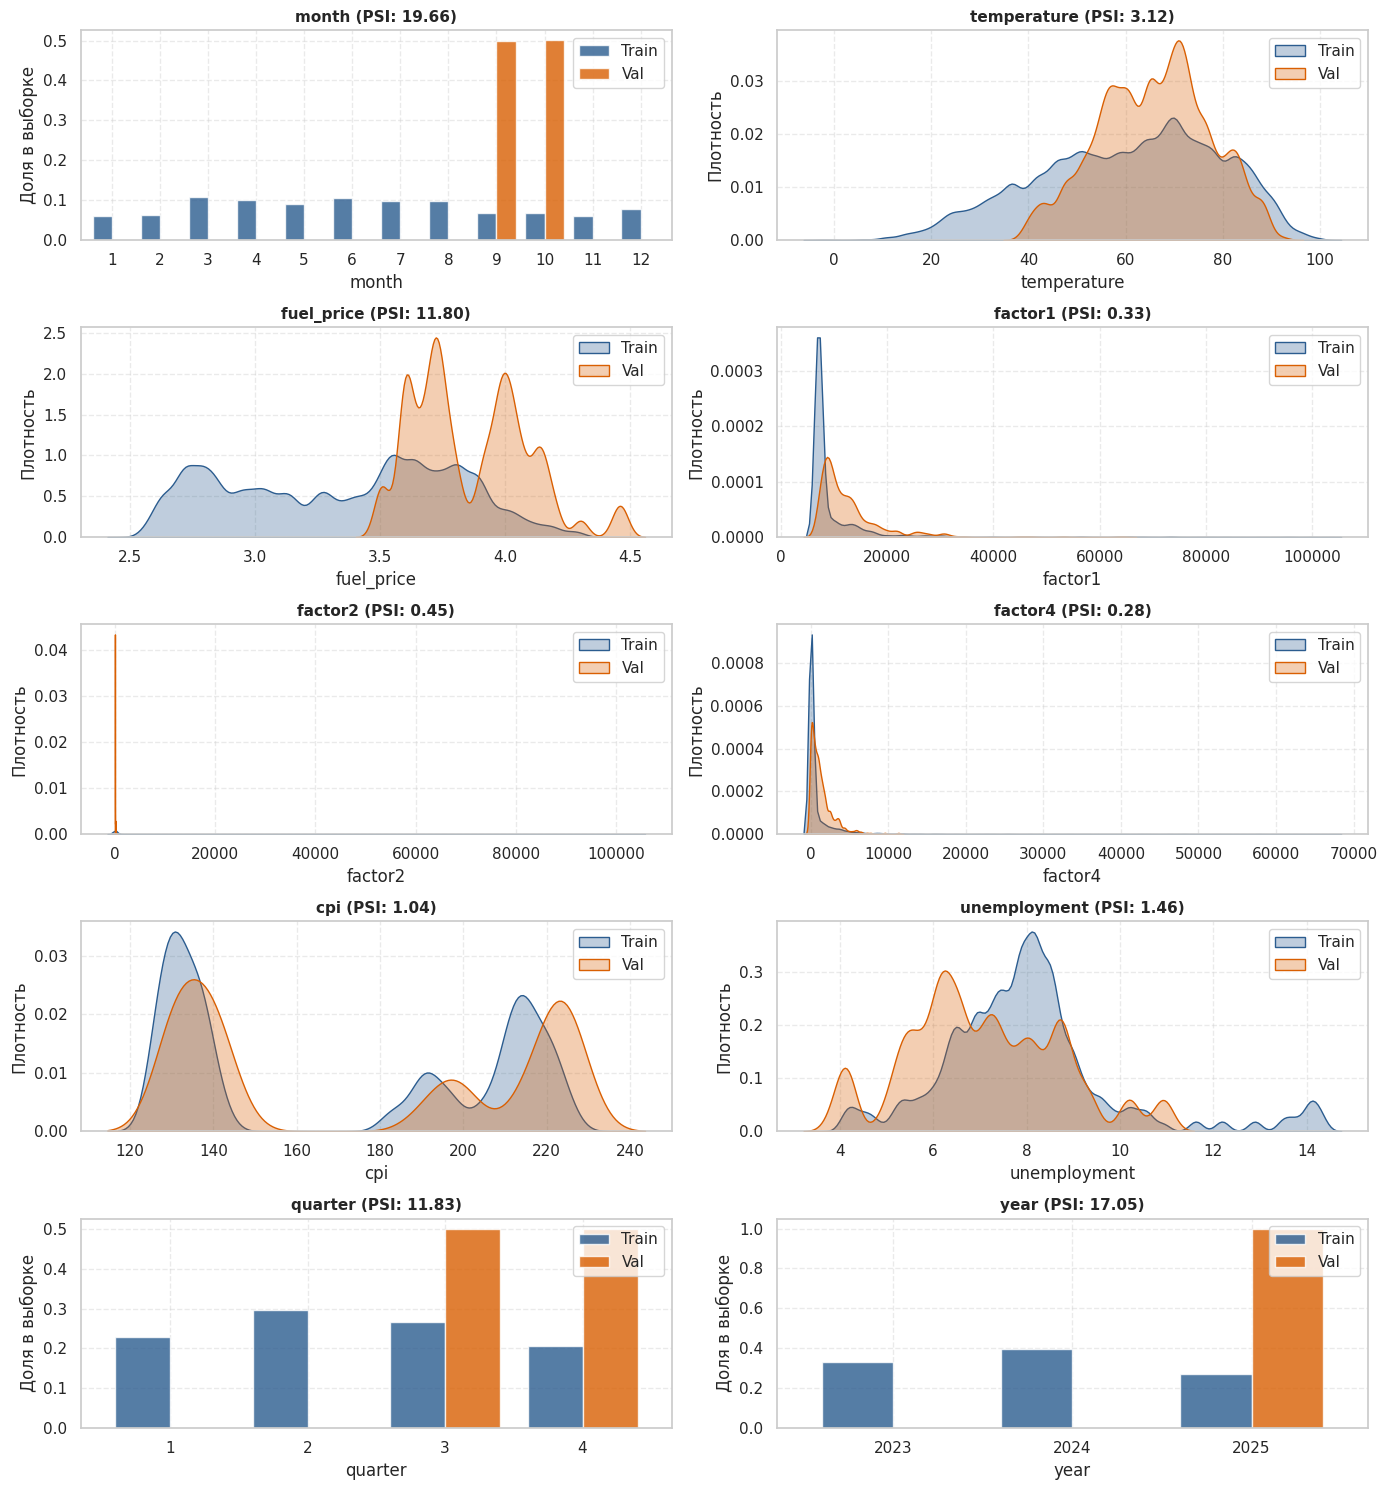

In [57]:
# Визуализация распределений

# Настраиваем размер и сетку (2 колонки для компактности)
num_cols = len(bad_psi)
fig, axes = plt.subplots(nrows=(num_cols + 1) // 2, ncols=2, figsize=(14, 3 * ((num_cols + 1) // 2)))
axes = axes.flatten()

# Единый стиль для всех графиков
color_train = '#2b5c8f'  # Синий для Train
color_val = '#d95f02'    # Оранжевый для Val

for i, col in enumerate(bad_psi):
    ax = axes[i]

    # 1. Если признак дискретный/календарный — строим простой Barplot
    if col in ['month', 'quarter', 'year']:
        # Считаем доли (проценты) каждого значения
        train_dist = train_data[col].value_counts(normalize=True).sort_index()
        val_dist = val_data[col].value_counts(normalize=True).sort_index()

        # Объединяем для удобного построения столбиков рядом
        df_bars = pd.DataFrame({'Train': train_dist, 'Val': val_dist}).fillna(0)
        df_bars.plot(kind='bar', ax=ax, color=[color_train, color_val], width=0.8, alpha=0.8)
        ax.set_ylabel('Доля в выборке')
        ax.tick_params(axis='x', rotation=0)

    # 2. Если признак непрерывный — строим сглаженную плотность (KDE)
    else:
        sns.kdeplot(train_data[col].dropna(), ax=ax, color=color_train, label='Train', fill=True, alpha=0.3)
        sns.kdeplot(val_data[col].dropna(), ax=ax, color=color_val, label='Val', fill=True, alpha=0.3)
        ax.set_ylabel('Плотность')

    # Настройки оформления
    psi_score = psi_results.get(col, 0)
    ax.set_title(f'{col} (PSI: {psi_score:.2f})', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='upper right')

# Убираем неиспользованные пустые ячейки графика, если число признаков нечётное
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Задача:** удалите признаки с PSI ≥ 0.2.

Признаки с высоким PSI нестабильны и могут ухудшить качество модели в будущем. Удалите их из обучающей и валидационной выборок.

In [58]:
# Удалите все признаки, у которых PSI ≥ 0.2
columns_to_drop = bad_psi
train_data = train_data.drop(columns=columns_to_drop)
val_data = val_data.drop(columns=columns_to_drop)

### Шаг 4. Обучение модели CatBoost

**Задача:** обучите модель CatBoost.

Используйте **обучающую** выборку.

In [59]:
# удаляем date
train_data.columns

Index(['store', 'dept', 'date', 'weekly_sales', 'is_holiday', 'type', 'size',
       'factor3', 'factor5', 'avg_sales_before', 'sales_1week_ago',
       'sales_2week_ago', 'sales_4week_ago', 'mean_sales_2week',
       'mean_sales_4week'],
      dtype='object')

In [60]:
# Определяем список всех признаков для обучения без целевой переменной 'weekly_sales'
feature_cols = [col for col in train_data.columns if col not in ['weekly_sales']]

# Указываем, какие из них являются категориальными
cat_features = ['store', 'dept', 'type', 'is_holiday']

# Приводим категориальные признаки к строковому типу (требование CatBoost)
for col in cat_features:
    train_data[col] = train_data[col].astype(str)
    val_data[col] = val_data[col].astype(str)

# Формируем обучающую и валидационную выборки (X, y)
X_train = train_data[feature_cols]
y_train = train_data['weekly_sales']

X_val = val_data[feature_cols]
y_val = val_data['weekly_sales']

In [61]:
# Инициализация модели
model = CatBoostRegressor(
    iterations=1000,           # Максимальное количество деревьев
    learning_rate=0.05,        # Скорость обучения (шаг градиентного спуска)
    depth=6,                   # Глубина деревьев (оптимально 4-8)
    loss_function='RMSE',      # Функция потерь для регрессии
    eval_metric='RMSE',        # Метрика оценки на валидации
    random_seed=RANDOM_STATE,  # Воспроизводимость результатов
    verbose=100                # Выводить лог обучения каждые 100 итераций
)

In [62]:
# Обучение модели
model.fit(
    X_train, y_train,
    cat_features=cat_features,
    eval_set=(X_val, y_val),
    use_best_model=True,       # Сохранить веса модели с наилучшим RMSE на валидации
    early_stopping_rounds=50
)

0:	learn: 21786.6291333	test: 20798.8653890	best: 20798.8653890 (0)	total: 450ms	remaining: 7m 29s
100:	learn: 5223.0850331	test: 3230.3687305	best: 3230.3687305 (100)	total: 38.6s	remaining: 5m 43s
200:	learn: 4601.9177838	test: 3208.0537747	best: 3206.9379522 (192)	total: 1m 16s	remaining: 5m 3s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 3196.169793
bestIteration = 216

Shrink model to first 217 iterations.


CatBoostRegressor(depth=6, eval_metric='RMSE', iterations=1000, learning_rate=0.05, loss_function='RMSE', random_seed=42, verbose=100)

In [63]:
# Метрики на обучающей выборке
# Получаем предсказания модели на обучающей выборке
y_pred_train = model.predict(X_train)

# Рассчитываем метрики
mae_train = mean_absolute_error(y_train, y_pred_train)
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
r2_train = r2_score(y_train, y_pred_train)

# Выводим результаты
print(f"MAE  (Средняя абсолютная ошибка): {mae_train:,.2f}")
print(f"RMSE (Корень из среднеквадр. ошибки): {rmse_train:,.2f}")
print(f"R²   (Коэффициент детерминации): {r2_train:.4f}")

MAE  (Средняя абсолютная ошибка): 1,803.54
RMSE (Корень из среднеквадр. ошибки): 4,550.41
R²   (Коэффициент детерминации): 0.9602


**Задача:** оцените качество модели на валидационной выборке.

Используйте метрики:
- **MAE**.
- **RMSE**.
- **R²**.

In [64]:
X_train.columns

Index(['store', 'dept', 'date', 'is_holiday', 'type', 'size', 'factor3',
       'factor5', 'avg_sales_before', 'sales_1week_ago', 'sales_2week_ago',
       'sales_4week_ago', 'mean_sales_2week', 'mean_sales_4week'],
      dtype='object')

In [65]:
X_val.columns

Index(['store', 'dept', 'date', 'is_holiday', 'type', 'size', 'factor3',
       'factor5', 'avg_sales_before', 'sales_1week_ago', 'sales_2week_ago',
       'sales_4week_ago', 'mean_sales_2week', 'mean_sales_4week'],
      dtype='object')

In [66]:
model.feature_names_

['store',
 'dept',
 'date',
 'is_holiday',
 'type',
 'size',
 'factor3',
 'factor5',
 'avg_sales_before',
 'sales_1week_ago',
 'sales_2week_ago',
 'sales_4week_ago',
 'mean_sales_2week',
 'mean_sales_4week']

In [67]:
# Получаем предсказания модели на валидационной выборке
y_pred = model.predict(X_val)

# Рассчитываем метрики
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

# Выводим результаты
print(f"MAE  (Средняя абсолютная ошибка): {mae:,.2f}")
print(f"RMSE (Корень из среднеквадр. ошибки): {rmse:,.2f}")
print(f"R²   (Коэффициент детерминации): {r2:.4f}")

MAE  (Средняя абсолютная ошибка): 1,496.25
RMSE (Корень из среднеквадр. ошибки): 3,196.17
R²   (Коэффициент детерминации): 0.9785


**Вывод:** В сравнении со значениями метрик на обучающей выборке и валидационной - переобучения не произошло

**Задача:** проанализируйте важность признаков.

Она показывает, какие признаки наиболее важны для модели:
- Проверьте, нет ли в топе признаков, которые могут приводить к утечке данных.
- Посмотрите, какие признаки действительно влияют на продажи.


=== ТОП-10 самых важных признаков ===
            feature  importance
0   sales_1week_ago   30.579780
1  mean_sales_4week   16.189586
2  mean_sales_2week   13.009512
3   sales_4week_ago    7.967472
4  avg_sales_before    6.656335
5              date    6.507512
6   sales_2week_ago    6.190995
7              dept    5.632448
8        is_holiday    3.582944
9           factor3    2.916660


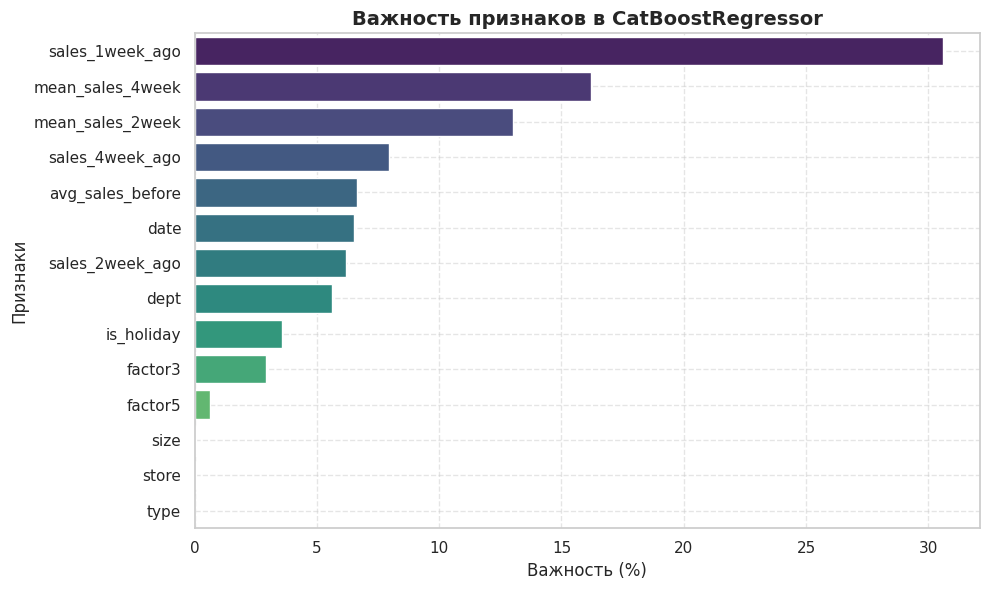

In [68]:
# 1. Получаем важность признаков из обученной модели
feature_importance = model.get_feature_importance()
feature_names = X_train.columns

# 2. Объединяем в DataFrame и сортируем по убыванию
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values(by='importance', ascending=False).reset_index(drop=True)

# Выводим Топ-10 признаков в виде таблицы
print("=== ТОП-10 самых важных признаков ===")
print(importance_df.head(10))

# 3. Визуализация
plt.figure(figsize=(10, 6))
sns.barplot(
    x='importance',
    y='feature',
    data=importance_df,
    palette='viridis'
)

plt.title('Важность признаков в CatBoostRegressor', fontsize=14, fontweight='bold')
plt.xlabel('Важность (%)', fontsize=12)
plt.ylabel('Признаки', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Выводы:**

- Самый важный признак для модели продажи предыдущей недели sales_1week_ago

- Также большую важность для модели имеют средние продажи 2 и 4 недели назад mean_sales_4week , mean_sales_2week, sales_4week_ago

- Наименее важными модель считает тип , размер даркстора и его идентификатор



**Задача:** сохраните обученную модель в S3.

Модель нужно сохранить для дальнейшего использования в batch-инференсе. Код уже реализован, необходимо просто его запустить.

**Важно:** не указывайте секреты явно в ноутбуке, используйте переменные окружения.

In [ ]:
# Ключи S3 и параметры БД хранятся в файле .env (шаблон: .env.example) и в ноутбук не записываются
from dotenv import load_dotenv
import os
load_dotenv()

required = ["S3_ACCESS_KEY_ID", "S3_SECRET_KEY", "S3_BUCKET"]
missing = [v for v in required if not os.getenv(v)]
assert not missing, f"В .env не заданы переменные: {missing}"
print("Переменные окружения для S3 найдены")

In [70]:
!pip install boto3 -q

In [71]:
import io
import pickle
import boto3
import os
from dotenv import load_dotenv
load_dotenv()

# Создаём клиент для подключения к S3
s3_client = boto3.client(
    's3',
    endpoint_url='https://storage.yandexcloud.net',
    aws_access_key_id=os.getenv('S3_ACCESS_KEY_ID'),
    aws_secret_access_key=os.getenv('S3_SECRET_KEY'),
    region_name='ru-central1'
)

# Сохраняем модель в буфер
filebuffer = io.BytesIO()
pickle.dump(model, filebuffer)
filebuffer.seek(0)

# Загружаем в S3
s3_client.upload_fileobj(
    Fileobj=filebuffer,
    Bucket=os.getenv('S3_BUCKET'),
    Key='catboost_model.pkl'
)

print("Модель успешно загружена в S3: catboost_model.pkl")

Модель успешно загружена в S3: catboost_model.pkl
